In [1]:
# Required libraries
import os
import requests
import pandas as pd
import joblib

from dotenv import load_dotenv

load_dotenv()

# Alpha Vantage API key
API_KEY = os.getenv("ALPHA_VANTAGE_API_KEY")

print("API Key Loaded:", API_KEY is not None)

API Key Loaded: True


In [2]:
# Alpha Vantage API endpoint
BASE_URL = "https://www.alphavantage.co/query"

# Which stock we want to predict
SYMBOL = "AAPL"


def fetch_market_data(symbol):
    """
    Alpha Vantage nundi latest available daily market data fetch chestundi.
    """

    params = {
        "function": "TIME_SERIES_DAILY",
        "symbol": symbol,
        "outputsize": "compact",
        "apikey": API_KEY
    }

    # API request
    response = requests.get(
        BASE_URL,
        params=params,
        timeout=30
    )

    
    response.raise_for_status()

    data = response.json()

    if "Time Series (Daily)" not in data:
        raise ValueError(
            f"API response lo market data ledu: {data}"
        )

    time_series = data["Time Series (Daily)"]

    # Dictionary → DataFrame
    df_live = pd.DataFrame.from_dict(
        time_series,
        orient="index"
    )

    df_live.columns = [
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ]

    # Date index
    df_live.index = pd.to_datetime(df_live.index)
    df_live.index.name = "Date"

    # Numeric conversion
    numeric_columns = [
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ]

    df_live[numeric_columns] = df_live[numeric_columns].astype(float)

    # Oldest → newest order
    df_live = df_live.sort_index()

    return df_live

In [3]:
# Fetch latest available market data
live_df = fetch_market_data(SYMBOL)

print("Live Data Shape:", live_df.shape)

print("\nLatest Market Data:")
display(live_df.tail())

Live Data Shape: (100, 5)

Latest Market Data:


,Open,High,Low,Close,Volume
Date,,,,,
2026-09-25,336.040,341.6700,334.5300,341.07,30002507.0
2026-09-28,340.370,342.9880,338.0400,338.40,32820848.0
2026-09-29,336.965,337.0850,328.7000,329.40,38478037.0
2026-09-30,330.800,339.5000,330.1401,333.02,49988558.0
2026-10-01,330.000,332.4816,325.8100,330.32,36306346.0


In [4]:
# Latest available trading day row
latest = live_df.iloc[-1]

print("Latest Available Date:", live_df.index[-1])

print("\nLatest Market Data:")
print("Open   :", latest["Open"])
print("High   :", latest["High"])
print("Low    :", latest["Low"])
print("Close  :", latest["Close"])
print("Volume :", latest["Volume"])

Latest Available Date: 2026-10-01 00:00:00

Latest Market Data:
Open   : 330.0
High   : 332.4816
Low    : 325.81
Close  : 330.32
Volume : 36306346.0


In [5]:
df_live = live_df.copy()


df_live["Daily_Return"] = df_live["Close"].pct_change()


# --------------------------------------------------
#   20-Day Volatility
# --------------------------------------------------
df_live["Volatility_20D"] = (
    df_live["Daily_Return"]
    .rolling(window=20)
    .std()
)


# --------------------------------------------------
#    20-Day Simple Moving Average
# --------------------------------------------------
df_live["SMA_20"] = (
    df_live["Close"]
    .rolling(window=20)
    .mean()
)


# --------------------------------------------------
#    20-Day Exponential Moving Average
# --------------------------------------------------
df_live["EMA_20"] = (
    df_live["Close"]
    .ewm(
        span=20,
        adjust=False
    )
    .mean()
)


# --------------------------------------------------
#    RSI - Relative Strength Index
# --------------------------------------------------
delta = df_live["Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss

df_live["RSI_14"] = (
    100 - (100 / (1 + rs))
)


# --------------------------------------------------
#    MACD
# --------------------------------------------------
ema_12 = df_live["Close"].ewm(
    span=12,
    adjust=False
).mean()

ema_26 = df_live["Close"].ewm(
    span=26,
    adjust=False
).mean()

df_live["MACD"] = ema_12 - ema_26


# MACD Signal Line
df_live["MACD_Signal"] = (
    df_live["MACD"]
    .ewm(
        span=9,
        adjust=False
    )
    .mean()
)


print("Technical indicators created successfully!")

Technical indicators created successfully!


In [6]:
df_live[[
    "Close",
    "Daily_Return",
    "Volatility_20D",
    "SMA_20",
    "EMA_20",
    "RSI_14",
    "MACD",
    "MACD_Signal"
]].tail()

,Close,Daily_Return,Volatility_20D,SMA_20,EMA_20,RSI_14,MACD,MACD_Signal
Date,,,,,,,,
2026-09-25,341.07,0.015331,0.014069,329.3960,330.352921,74.398705,6.198384,5.389505
2026-09-28,338.40,-0.007828,0.014007,330.3310,331.119309,76.304554,6.067033,5.525011
2026-09-29,329.40,-0.026596,0.015294,330.9585,330.955565,63.981702,5.177034,5.455415
2026-09-30,333.02,0.010990,0.014387,331.3530,331.152178,57.558003,4.709519,5.306236
2026-10-01,330.32,-0.008108,0.014536,331.6210,331.072923,47.542223,4.074178,5.059825


In [7]:
# --------------------------------------------------
# Lag Features
# --------------------------------------------------

# Previous trading day's Close
df_live["Close_Lag_1"] = df_live["Close"].shift(1)

# Close price from 2 trading days ago
df_live["Close_Lag_2"] = df_live["Close"].shift(2)

# Close price from 5 trading days ago
df_live["Close_Lag_5"] = df_live["Close"].shift(5)

# Previous trading day's return
df_live["Return_Lag_1"] = df_live["Daily_Return"].shift(1)

# Previous trading day's volume
df_live["Volume_Lag_1"] = df_live["Volume"].shift(1)

print("Lag features created successfully!")

Lag features created successfully!


In [8]:
features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "Volatility_20D",
    "SMA_20",
    "EMA_20",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "Close_Lag_1",
    "Close_Lag_2",
    "Close_Lag_5",
    "Return_Lag_1",
    "Volume_Lag_1"
]

print("Number of features:", len(features))
print("\nFeatures:")
print(features)

Number of features: 17

Features:
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Volatility_20D', 'SMA_20', 'EMA_20', 'RSI_14', 'MACD', 'MACD_Signal', 'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'Return_Lag_1', 'Volume_Lag_1']


In [9]:
# Select only the features used during training
latest_data = df_live[features].dropna().tail(1)

print("Latest Feature Row:")
display(latest_data)

Latest Feature Row:


,Open,High,Low,Close,Volume,Daily_Return,Volatility_20D,SMA_20,EMA_20,RSI_14,MACD,MACD_Signal,Close_Lag_1,Close_Lag_2,Close_Lag_5,Return_Lag_1,Volume_Lag_1
Date,,,,,,,,,,,,,,,,,
2026-10-01,330.0,332.4816,325.81,330.32,36306346.0,-0.008108,0.014536,331.621,331.072923,47.542223,4.074178,5.059825,333.02,329.4,335.92,0.01099,49988558.0


In [10]:
import joblib
import os

# Saved model file path
MODEL_PATH = "models/random_forest_model.pkl"

# Feature list file path
FEATURE_PATH = "models/feature_list.pkl"

# Check files exist
print("Model exists:", os.path.exists(MODEL_PATH))
print("Feature list exists:", os.path.exists(FEATURE_PATH))

Model exists: True
Feature list exists: True


In [11]:
# Load trained Random Forest model
model = joblib.load(MODEL_PATH)

# Load exact feature list used during training
feature_list = joblib.load(FEATURE_PATH)

print("Model loaded successfully!")
print("Number of features:", len(feature_list))
print("\nFeatures:")
print(feature_list)

Model loaded successfully!
Number of features: 17

Features:
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Volatility_20D', 'SMA_20', 'EMA_20', 'RSI_14', 'MACD', 'MACD_Signal', 'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'Return_Lag_1', 'Volume_Lag_1']


In [12]:
# Select exactly the same 17 features used during training
latest_data = df_live[feature_list].dropna().tail(1)

print("Prediction Input Shape:", latest_data.shape)
display(latest_data)

Prediction Input Shape: (1, 17)


,Open,High,Low,Close,Volume,Daily_Return,Volatility_20D,SMA_20,EMA_20,RSI_14,MACD,MACD_Signal,Close_Lag_1,Close_Lag_2,Close_Lag_5,Return_Lag_1,Volume_Lag_1
Date,,,,,,,,,,,,,,,,,
2026-10-01,330.0,332.4816,325.81,330.32,36306346.0,-0.008108,0.014536,331.621,331.072923,47.542223,4.074178,5.059825,333.02,329.4,335.92,0.01099,49988558.0


In [13]:
# Predict the next trading day's closing price
prediction = model.predict(latest_data)

# Extract the predicted value
predicted_close = prediction[0]

print("Predicted Next-Day Close:", predicted_close)

Predicted Next-Day Close: 325.3549000000005


In [14]:
# Get the latest available closing price
current_close = live_df["Close"].iloc[-1]

# Calculate expected percentage change from current close
expected_change = (
    (predicted_close - current_close)
    / current_close
) * 100

print("Latest Close       :", current_close)
print("Predicted Next Close:", predicted_close)
print("Expected Change (%) :", expected_change)

Latest Close       : 330.32
Predicted Next Close: 325.3549000000005
Expected Change (%) : -1.5031181884231941


In [15]:
print("=" * 45)
print("       NEXT-DAY MARKET PREDICTION")
print("=" * 45)

print(f"Symbol              : {SYMBOL}")
print(f"Latest Date         : {live_df.index[-1].date()}")
print(f"Latest Close        : ${current_close:.2f}")
print(f"Predicted Next Close: ${predicted_close:.2f}")
print(f"Expected Change     : {expected_change:+.2f}%")

print("=" * 45)

       NEXT-DAY MARKET PREDICTION
Symbol              : AAPL
Latest Date         : 2026-10-01
Latest Close        : $330.32
Predicted Next Close: $325.35
Expected Change     : -1.50%


In [16]:
# Store the live prediction result in a DataFrame

prediction_result = pd.DataFrame({
    "Symbol": [SYMBOL],
    "Latest_Date": [live_df.index[-1]],
    "Current_Close": [current_close],
    "Predicted_Next_Close": [predicted_close],
    "Expected_Change_Percent": [expected_change]
})

prediction_result

,Symbol,Latest_Date,Current_Close,Predicted_Next_Close,Expected_Change_Percent
0,AAPL,2026-10-01,330.32,325.3549,-1.503118


In [17]:
# Create predictions folder
os.makedirs("data", exist_ok=True)

# Save latest prediction
prediction_result.to_csv(
    "data/latest_prediction.csv",
    index=False
)

print("Prediction result saved successfully!")

Prediction result saved successfully!


In [18]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Original historical data load
df = pd.read_csv(
    "data/market_data.csv",
    index_col="Date",
    parse_dates=True
)

# Same technical indicators
df["Daily_Return"] = df["Close"].pct_change()

df["Volatility_20D"] = (
    df["Daily_Return"]
    .rolling(window=20)
    .std()
)

df["SMA_20"] = (
    df["Close"]
    .rolling(window=20)
    .mean()
)

df["EMA_20"] = (
    df["Close"]
    .ewm(span=20, adjust=False)
    .mean()
)

# RSI
delta = df["Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss

df["RSI_14"] = 100 - (100 / (1 + rs))

# MACD
ema_12 = df["Close"].ewm(
    span=12,
    adjust=False
).mean()

ema_26 = df["Close"].ewm(
    span=26,
    adjust=False
).mean()

df["MACD"] = ema_12 - ema_26

df["MACD_Signal"] = df["MACD"].ewm(
    span=9,
    adjust=False
).mean()

# Lag features
df["Close_Lag_1"] = df["Close"].shift(1)
df["Close_Lag_2"] = df["Close"].shift(2)
df["Close_Lag_5"] = df["Close"].shift(5)

df["Return_Lag_1"] = df["Daily_Return"].shift(1)
df["Volume_Lag_1"] = df["Volume"].shift(1)

# Target
df["Target_Close"] = df["Close"].shift(-1)

# Same features used during training
model_data = df[feature_list + ["Target_Close"]].dropna()

X = model_data[feature_list]
y = model_data["Target_Close"]

# Same chronological 80/20 split
train_size = int(len(model_data) * 0.80)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

# Predict test data using saved Random Forest
y_pred_rf = model.predict(X_test)

print("Historical predictions created successfully!")

print("Test samples:", len(y_test))

Historical predictions created successfully!
Test samples: 16


In [19]:
actual_vs_predicted = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_rf
}, index=y_test.index)

actual_vs_predicted.head()

,Actual,Predicted
Date,,
2026-08-21,310.34,312.064225
2026-08-24,309.90,310.001675
2026-08-25,313.45,311.738163
2026-08-26,314.58,313.143750
2026-08-27,319.70,312.623250


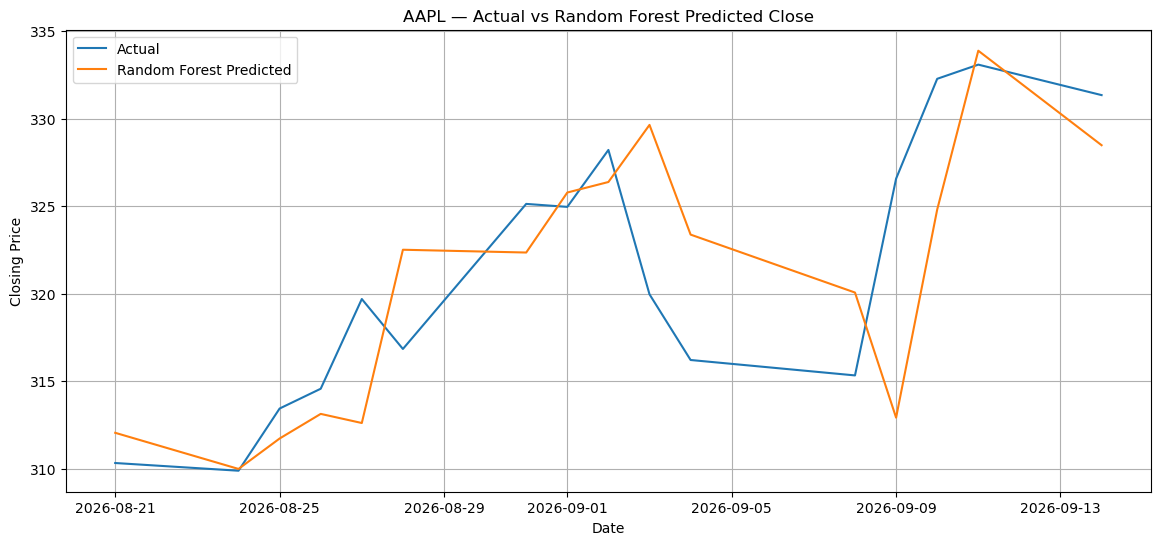

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    actual_vs_predicted.index,
    actual_vs_predicted["Actual"],
    label="Actual"
)

plt.plot(
    actual_vs_predicted.index,
    actual_vs_predicted["Predicted"],
    label="Random Forest Predicted"
)

plt.title("AAPL — Actual vs Random Forest Predicted Close")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.legend()
plt.grid(True)

plt.show()

In [21]:
from src.data_loader import fetch_market_data

In [22]:
SYMBOL = "AAPL"

live_df_test = fetch_market_data(SYMBOL)

print("Shape:", live_df_test.shape)

display(live_df_test.tail())

Shape: (100, 5)


,Open,High,Low,Close,Volume
Date,,,,,
2026-09-25,336.040,341.6700,334.5300,341.07,30002507.0
2026-09-28,340.370,342.9880,338.0400,338.40,32820848.0
2026-09-29,336.965,337.0850,328.7000,329.40,38478037.0
2026-09-30,330.800,339.5000,330.1401,333.02,49988558.0
2026-10-01,330.000,332.4816,325.8100,330.32,36306346.0


In [23]:
from src.data_loader import fetch_market_data
from src.features import create_features, get_model_features

SYMBOL = "AAPL"

live_df = fetch_market_data(SYMBOL)

print("Raw Data:")
display(live_df.tail())

Raw Data:


,Open,High,Low,Close,Volume
Date,,,,,
2026-09-25,336.040,341.6700,334.5300,341.07,30002507.0
2026-09-28,340.370,342.9880,338.0400,338.40,32820848.0
2026-09-29,336.965,337.0850,328.7000,329.40,38478037.0
2026-09-30,330.800,339.5000,330.1401,333.02,49988558.0
2026-10-01,330.000,332.4816,325.8100,330.32,36306346.0


In [24]:
featured_df = create_features(live_df)

print("Feature Engineering Completed!")

display(
    featured_df.tail()
)

Feature Engineering Completed!


,Open,High,Low,Close,Volume,Daily_Return,Volatility_20D,SMA_20,EMA_20,RSI_14,MACD,MACD_Signal,Close_Lag_1,Close_Lag_2,Close_Lag_5,Return_Lag_1,Volume_Lag_1
Date,,,,,,,,,,,,,,,,,
2026-09-25,336.040,341.6700,334.5300,341.07,30002507.0,0.015331,0.014069,329.3960,330.352921,74.398705,6.198384,5.389505,335.92,337.02,336.13,-0.003264,24733098.0
2026-09-28,340.370,342.9880,338.0400,338.40,32820848.0,-0.007828,0.014007,330.3310,331.119309,76.304554,6.067033,5.525011,341.07,335.92,338.98,0.015331,30002507.0
2026-09-29,336.965,337.0850,328.7000,329.40,38478037.0,-0.026596,0.015294,330.9585,330.955565,63.981702,5.177034,5.455415,338.40,341.07,339.75,-0.007828,32820848.0
2026-09-30,330.800,339.5000,330.1401,333.02,49988558.0,0.010990,0.014387,331.3530,331.152178,57.558003,4.709519,5.306236,329.40,338.40,337.02,-0.026596,38478037.0
2026-10-01,330.000,332.4816,325.8100,330.32,36306346.0,-0.008108,0.014536,331.6210,331.072923,47.542223,4.074178,5.059825,333.02,329.40,335.92,0.010990,49988558.0


In [25]:
X_live = get_model_features(featured_df)

print("Model Input Shape:", X_live.shape)

display(X_live.tail())

Model Input Shape: (80, 17)


,Open,High,Low,Close,Volume,Daily_Return,Volatility_20D,SMA_20,EMA_20,RSI_14,MACD,MACD_Signal,Close_Lag_1,Close_Lag_2,Close_Lag_5,Return_Lag_1,Volume_Lag_1
Date,,,,,,,,,,,,,,,,,
2026-09-25,336.040,341.6700,334.5300,341.07,30002507.0,0.015331,0.014069,329.3960,330.352921,74.398705,6.198384,5.389505,335.92,337.02,336.13,-0.003264,24733098.0
2026-09-28,340.370,342.9880,338.0400,338.40,32820848.0,-0.007828,0.014007,330.3310,331.119309,76.304554,6.067033,5.525011,341.07,335.92,338.98,0.015331,30002507.0
2026-09-29,336.965,337.0850,328.7000,329.40,38478037.0,-0.026596,0.015294,330.9585,330.955565,63.981702,5.177034,5.455415,338.40,341.07,339.75,-0.007828,32820848.0
2026-09-30,330.800,339.5000,330.1401,333.02,49988558.0,0.010990,0.014387,331.3530,331.152178,57.558003,4.709519,5.306236,329.40,338.40,337.02,-0.026596,38478037.0
2026-10-01,330.000,332.4816,325.8100,330.32,36306346.0,-0.008108,0.014536,331.6210,331.072923,47.542223,4.074178,5.059825,333.02,329.40,335.92,0.010990,49988558.0


In [26]:
print("Number of Features:", len(X_live.columns))

print("\nFeature Names:")
print(X_live.columns.tolist())

Number of Features: 17

Feature Names:
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Volatility_20D', 'SMA_20', 'EMA_20', 'RSI_14', 'MACD', 'MACD_Signal', 'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'Return_Lag_1', 'Volume_Lag_1']


In [27]:
print(
    X_live.columns.tolist()
    == feature_list
)

True


In [28]:
from src.data_loader import fetch_market_data
from src.features import create_features, get_model_features

from src.prediction import (
    load_model,
    load_feature_list,
    predict_next_close,
    calculate_expected_change
)

In [29]:
SYMBOL = "AAPL"

live_df = fetch_market_data(SYMBOL)

print("Live data fetched successfully!")

Live data fetched successfully!


In [30]:
featured_df = create_features(live_df)

X_live = get_model_features(featured_df)

print("Feature engineering completed!")
print("Shape:", X_live.shape)

Feature engineering completed!
Shape: (80, 17)


In [31]:
model = load_model()

feature_list = load_feature_list()

print("Model loaded successfully!")
print("Features:", len(feature_list))

Model loaded successfully!
Features: 17


In [32]:
X_live = X_live[feature_list]

print(
    "Feature Order Correct:",
    X_live.columns.tolist() == feature_list
)

Feature Order Correct: True


In [33]:
# Latest available feature row
latest_features = X_live.tail(1)

# Current/latest closing price
current_close = live_df["Close"].iloc[-1]

# Predict next trading day's close
predicted_close = predict_next_close(
    model,
    latest_features
)

# Calculate percentage difference
expected_change = calculate_expected_change(
    current_close,
    predicted_close
)

In [34]:
print("=" * 50)
print("       NEXT-DAY MARKET PREDICTION")
print("=" * 50)

print(f"Symbol               : {SYMBOL}")
print(f"Latest Date          : {live_df.index[-1].date()}")
print(f"Latest Close         : ${current_close:.2f}")
print(f"Predicted Next Close : ${predicted_close:.2f}")
print(f"Expected Change      : {expected_change:+.2f}%")

print("=" * 50)

       NEXT-DAY MARKET PREDICTION
Symbol               : AAPL
Latest Date          : 2026-10-01
Latest Close         : $330.32
Predicted Next Close : $325.35
Expected Change      : -1.50%


In [35]:
from src.models import (
    create_linear_regression,
    create_ridge_regression,
    create_decision_tree,
    create_random_forest,
    create_gradient_boosting
)

In [36]:
lr = create_linear_regression()
ridge = create_ridge_regression()
dt = create_decision_tree()
rf = create_random_forest()
gb = create_gradient_boosting()

print("All models created successfully!")

All models created successfully!


In [37]:
from src.data_loader import fetch_market_data
from src.features import create_features, get_model_features
from src.prediction import (
    load_model,
    load_feature_list,
    predict_next_close,
    calculate_expected_change
)

# Stock symbol
SYMBOL = "AAPL"

# 1. Fetch live market data
live_df = fetch_market_data(SYMBOL)

# 2. Create all features
featured_df = create_features(live_df)

# 3. Select model features
X_live = get_model_features(featured_df)

# 4. Load saved model
model = load_model()

# 5. Load training feature order
feature_list = load_feature_list()

# 6. Ensure exact feature order
X_live = X_live[feature_list]

# 7. Take latest row
latest_features = X_live.tail(1)

# 8. Current close
current_close = live_df["Close"].iloc[-1]

# 9. Predict next-day close
predicted_close = predict_next_close(
    model,
    latest_features
)

# 10. Calculate expected percentage change
expected_change = calculate_expected_change(
    current_close,
    predicted_close
)

# Display result
print("=" * 50)
print("       LIVE MARKET PREDICTION")
print("=" * 50)

print(f"Symbol               : {SYMBOL}")
print(f"Latest Date          : {live_df.index[-1].date()}")
print(f"Latest Close         : ${current_close:.2f}")
print(f"Predicted Next Close : ${predicted_close:.2f}")
print(f"Expected Change      : {expected_change:+.2f}%")

print("=" * 50)

       LIVE MARKET PREDICTION
Symbol               : AAPL
Latest Date          : 2026-10-01
Latest Close         : $330.32
Predicted Next Close : $325.35
Expected Change      : -1.50%


In [39]:
actual_vs_predicted = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_rf
}, index=y_test.index)

actual_vs_predicted.to_csv(
    "data/actual_vs_predicted.csv"
)

print("Historical prediction file saved successfully!")

Historical prediction file saved successfully!


In [40]:
import os

print(
    os.path.exists(
        "data/actual_vs_predicted.csv"
    )
)

True
